<a href="https://colab.research.google.com/github/Malak0Ahmed/Satellite-Image-Classification/blob/main/AI_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!unzip dataset.zip

Streaming output truncated to the last 5000 lines.
  inflating: data/cloudy/train_23566.jpg  
  inflating: data/cloudy/train_23598.jpg  
  inflating: data/cloudy/train_23608.jpg  
  inflating: data/cloudy/train_23634.jpg  
  inflating: data/cloudy/train_23636.jpg  
  inflating: data/cloudy/train_23646.jpg  
  inflating: data/cloudy/train_2366.jpg  
  inflating: data/cloudy/train_23664.jpg  
  inflating: data/cloudy/train_23706.jpg  
  inflating: data/cloudy/train_2380.jpg  
  inflating: data/cloudy/train_23805.jpg  
  inflating: data/cloudy/train_23806.jpg  
  inflating: data/cloudy/train_23826.jpg  
  inflating: data/cloudy/train_23843.jpg  
  inflating: data/cloudy/train_23877.jpg  
  inflating: data/cloudy/train_23884.jpg  
  inflating: data/cloudy/train_23953.jpg  
  inflating: data/cloudy/train_2396.jpg  
  inflating: data/cloudy/train_23978.jpg  
  inflating: data/cloudy/train_23979.jpg  
  inflating: data/cloudy/train_23980.jpg  
  inflating: data/cloudy/train_23981.jpg  
  infl

#Imports

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import itertools
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.applications import MobileNet, ResNet50
from sklearn.metrics import classification_report, confusion_matrix

# Configuration

In [ ]:
data_dir = 'Satellite_Image'
img_height = 128
img_width = 128
batch_size = 32
seed_value = 123
num_classes = 4

# Load datasets with splitting 70% / 30%

In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.3,
    subset="training",
    seed=seed_value,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.3,
    subset="validation",
    seed=seed_value,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

class_names_list = train_ds.class_names

Found 5631 files belonging to 4 classes.
Using 3942 files for training.
Found 5631 files belonging to 4 classes.
Using 1689 files for validation.


# NumPy Conversion

In [ ]:
def dataset_to_numpy(dataset):
    images, labels = [], []
    for image_batch, label_batch in dataset.as_numpy_iterator():
        images.append(image_batch)
        labels.append(label_batch)
    return np.concatenate(images, axis=0), np.concatenate(labels, axis=0)

train_X, train_y_int = dataset_to_numpy(train_ds)
test_X, test_y_int = dataset_to_numpy(test_ds)

# Normalization

In [ ]:
train_X = train_X.astype('float32') / 255.0
test_X = test_X.astype('float32') / 255.0

# Encoding

In [ ]:
train_y = to_categorical(train_y_int, num_classes=num_classes)
test_y = to_categorical(test_y_int, num_classes=num_classes)

In [ ]:
print(f"Dataset Shapes: Train {train_X.shape}, Test {test_X.shape}")

Dataset Shapes: Train (3942, 128, 128, 3), Test (1689, 128, 128, 3)


# Metrics & Grid Plotting Function

In [ ]:
def plot_and_evaluate(model, history, test_X, test_y, class_names):

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Acc')
    plt.plot(history.history['val_accuracy'], label='Val Acc')
    plt.title('Accuracy Curves')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title('Loss Curves')
    plt.legend()
    plt.show()

    y_pred_probs = model.predict(test_X, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = np.argmax(test_y, axis=1)

    print(f"Training Accuracy: {history.history['accuracy'][-1]*100:.2f}%")
    print(f"Test Accuracy: {model.evaluate(test_X, test_y, verbose=0)[1]*100:.2f}%")
    print("\nClassification Report:\n", classification_report(y_true, y_pred, target_names=class_names))

    cm = confusion_matrix(y_true, y_pred)
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    for i, normalize in enumerate([False, True]):
        curr_ax = axes[i]
        curr_cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] if normalize else cm
        title = 'Normalized Confusion Matrix' if normalize else 'Confusion Matrix'

        im = curr_ax.imshow(curr_cm, interpolation='nearest', cmap=plt.cm.Blues)
        curr_ax.set_title(title)
        fig.colorbar(im, ax=curr_ax)

        tick_marks = np.arange(len(class_names))
        curr_ax.set_xticks(tick_marks)
        curr_ax.set_xticklabels(class_names, rotation=45)
        curr_ax.set_yticks(tick_marks)
        curr_ax.set_yticklabels(class_names)

        fmt = '.2f' if normalize else 'd'
        thresh = curr_cm.max() / 2.
        for r, c in itertools.product(range(curr_cm.shape[0]), range(curr_cm.shape[1])):
            curr_ax.text(c, r, format(curr_cm[r, c], fmt),
                         horizontalalignment="center",
                         color="white" if curr_cm[r, c] > thresh else "black")
        curr_ax.set_ylabel('True label')
        curr_ax.set_xlabel('Predicted label')

    plt.tight_layout()
    plt.show()

# Early Stopping

In [ ]:
early_stopping = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

# Custom CNN Model

This code defines a simple CNN model that learns features directly from the input images using two convolutional layers with ReLU activation and max-pooling to reduce spatial size. After feature extraction, the output is flattened and passed to a small fully connected layer for learning high-level representations, and finally to a softmax layer that produces class probabilities. This model is lightweight and suitable for basic image classification tasks.

In [ ]:
model_cnn = Sequential([
    Conv2D(64, (3,3), input_shape=(img_height, img_width, 3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(num_classes, activation='softmax')
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model_cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [ ]:
model_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     3,686,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,725,444 (14.21 MB)

 Trainable params: 3,725,444 (14.21 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history_cnn = model_cnn.fit(train_X, train_y, epochs=200, validation_data=(test_X, test_y), callbacks=[early_stopping])

Epoch 1/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 114s 913ms/step - accuracy: 0.7555 - loss: 0.5214 - val_accuracy: 0.9183 - val_loss: 0.2023
Epoch 2/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 112s 906ms/step - accuracy: 0.9017 - loss: 0.2174 - val_accuracy: 0.8774 - val_loss: 0.2352
Epoch 3/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 138s 875ms/step - accuracy: 0.9191 - loss: 0.1804 - val_accuracy: 0.9195 - val_loss: 0.1741
Epoch 4/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 134s 811ms/step - accuracy: 0.9028 - loss: 0.2060 - val_accuracy: 0.9189 - val_loss: 0.1862
Epoch 5/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 149s 866ms/step - accuracy: 0.9183 - loss: 0.1847 - val_accuracy: 0.9307 - val_loss: 0.1509
Epoch 6/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 148s 912ms/step - accuracy: 0.9247 - loss: 0.1507 - val_accuracy: 0.9153 - val_loss: 0.1735
Epoch 7/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 115s 929ms/step - accuracy: 0.9228 - loss: 0.1648 - val_accuracy: 0.9195 - val_loss: 0.1667
Epoch 8/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 114s 918ms/step - accuracy: 

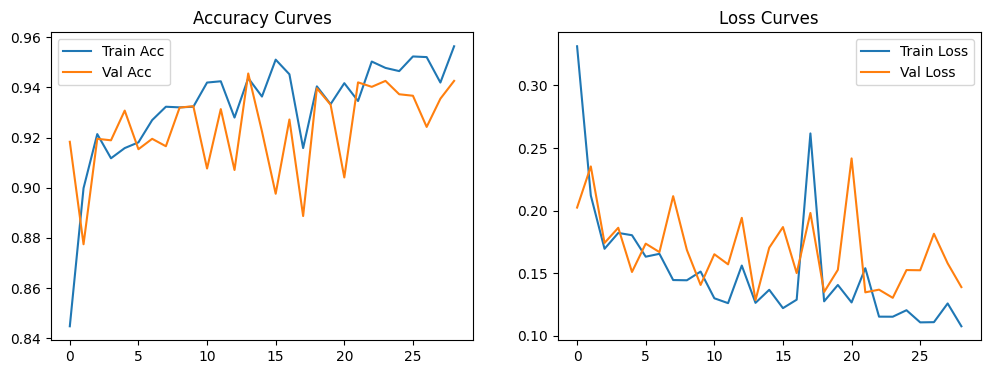

Training Accuracy: 95.64%
Test Accuracy: 94.55%

Classification Report:
               precision    recall  f1-score   support

      cloudy       1.00      1.00      1.00       428
      desert       1.00      1.00      1.00       367
  green_area       0.86      0.96      0.90       451
       water       0.95      0.84      0.89       443

    accuracy                           0.95      1689
   macro avg       0.95      0.95      0.95      1689
weighted avg       0.95      0.95      0.95      1689



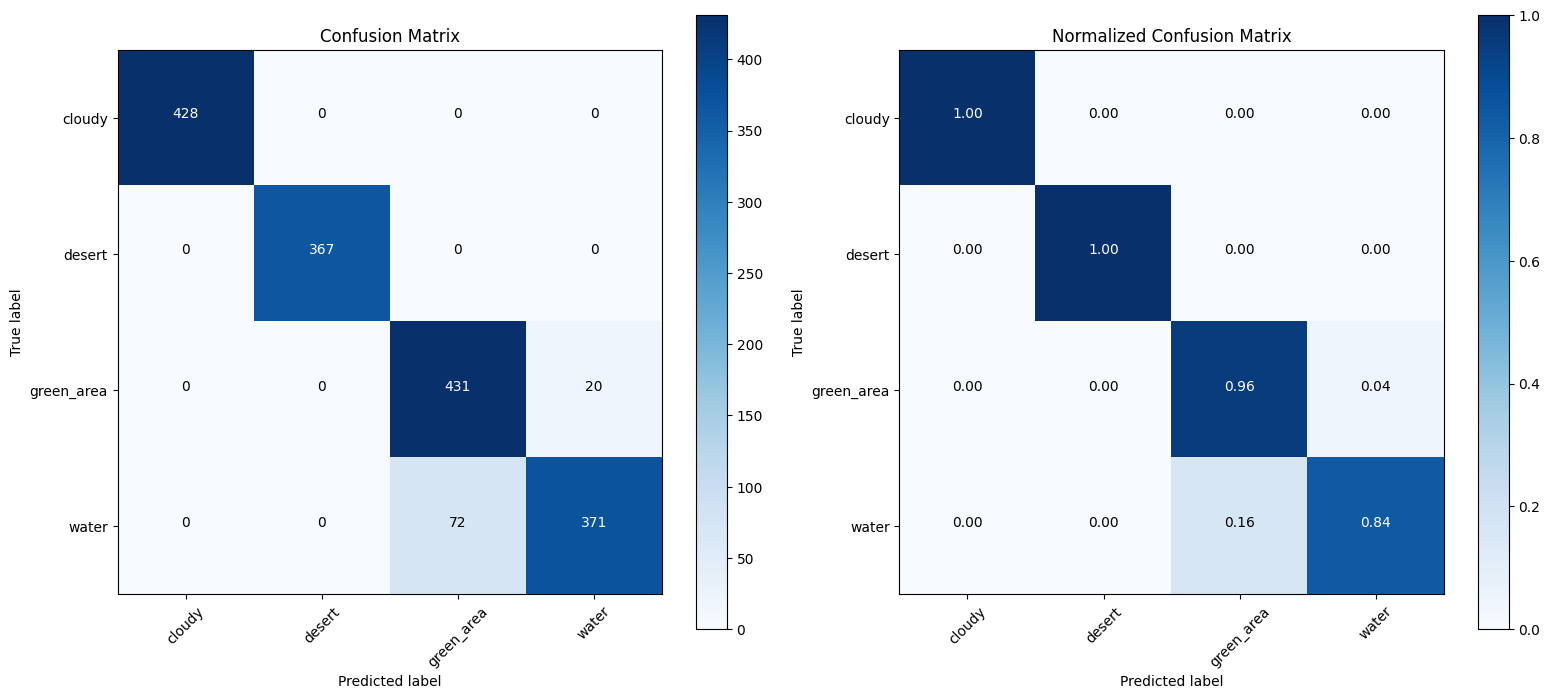

In [ ]:
plot_and_evaluate(model_cnn, history_cnn, test_X, test_y, class_names_list)

# AlexNet Model

This code defines an AlexNet-like convolutional neural network where the early convolution and pooling layers (base_1 to base_5) are used to extract visual features from input images, progressing from simple edges to more complex patterns. These base layers are frozen to prevent their weights from being updated during training, which is common in transfer learning. The flattened feature maps are then passed through fully connected layers with ReLU activation and dropout to reduce overfitting, and the final softmax layer outputs the class probabilities for classification.

In [ ]:
model_alex = Sequential([
    Conv2D(96, (11,11), strides=4, padding='same', activation='relu', input_shape=(128,128,3), name='base_1'),
    MaxPooling2D(3,2),
    Conv2D(256, (5,5), padding='same', activation='relu', name='base_2'),
    MaxPooling2D(3,2),
    Conv2D(384, (3,3), padding='same', activation='relu', name='base_3'),
    Conv2D(384, (3,3), padding='same', activation='relu', name='base_4'),
    Conv2D(256, (3,3), padding='same', activation='relu', name='base_5'),
    MaxPooling2D(3,2),
    Flatten(),
    Dense(4096, activation='relu'),
    Dropout(0.5),
    Dense(4096, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

for layer in model_alex.layers:
    if 'base' in layer.name: layer.trainable = False

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model_alex.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [ ]:
model_alex.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ base_1 (Conv2D)                 │ (None, 32, 32, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 15, 15, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ base_2 (Conv2D)                 │ (None, 15, 15, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ base_3 (Conv2D)                 │ (None, 7, 7, 384)      │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ base_4 (Conv2D)                 │ (None, 7, 7, 384)      │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ base_5 (Conv2D)                 │ (None, 7, 7, 256)      │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 3, 3, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4096)           │     9,441,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4)              │        16,388 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,986,180 (114.39 MB)

 Trainable params: 26,238,980 (100.09 MB)

 Non-trainable params: 3,747,200 (14.29 MB)

In [ ]:
history_alex = model_alex.fit(train_X, train_y, epochs=200, validation_data=(test_X, test_y), callbacks=[early_stopping])

Epoch 1/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 84s 667ms/step - accuracy: 0.6423 - loss: 0.7245 - val_accuracy: 0.7993 - val_loss: 0.3264
Epoch 2/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 148s 717ms/step - accuracy: 0.8148 - loss: 0.3220 - val_accuracy: 0.8893 - val_loss: 0.2411
Epoch 3/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 140s 704ms/step - accuracy: 0.8836 - loss: 0.2548 - val_accuracy: 0.9076 - val_loss: 0.1943
Epoch 4/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 86s 697ms/step - accuracy: 0.9171 - loss: 0.2004 - val_accuracy: 0.9053 - val_loss: 0.1906
Epoch 5/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 81s 656ms/step - accuracy: 0.9073 - loss: 0.2267 - val_accuracy: 0.9224 - val_loss: 0.2041
Epoch 6/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 83s 667ms/step - accuracy: 0.8989 - loss: 0.2163 - val_accuracy: 0.9242 - val_loss: 0.1743
Epoch 7/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 147s 711ms/step - accuracy: 0.9176 - loss: 0.1864 - val_accuracy: 0.9118 - val_loss: 0.1872
Epoch 8/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 140s 695ms/step - accuracy: 0.91

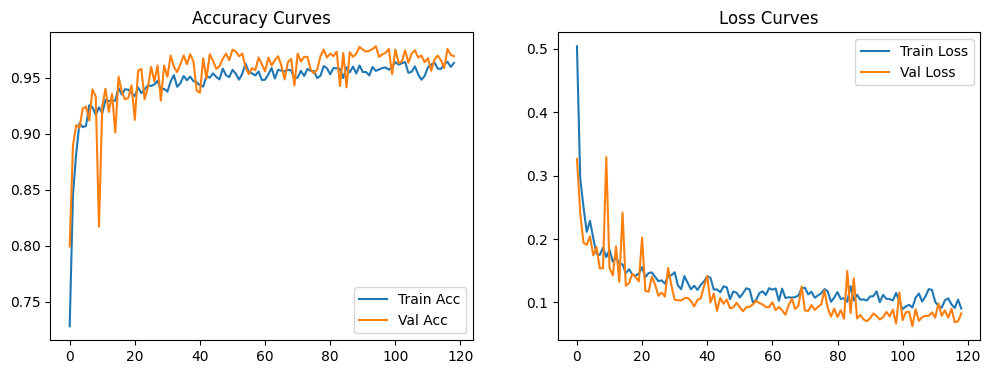

Training Accuracy: 96.32%
Test Accuracy: 97.45%

Classification Report:
               precision    recall  f1-score   support

      cloudy       1.00      1.00      1.00       428
      desert       1.00      1.00      1.00       367
  green_area       0.94      0.97      0.95       451
       water       0.97      0.94      0.95       443

    accuracy                           0.97      1689
   macro avg       0.98      0.98      0.98      1689
weighted avg       0.97      0.97      0.97      1689



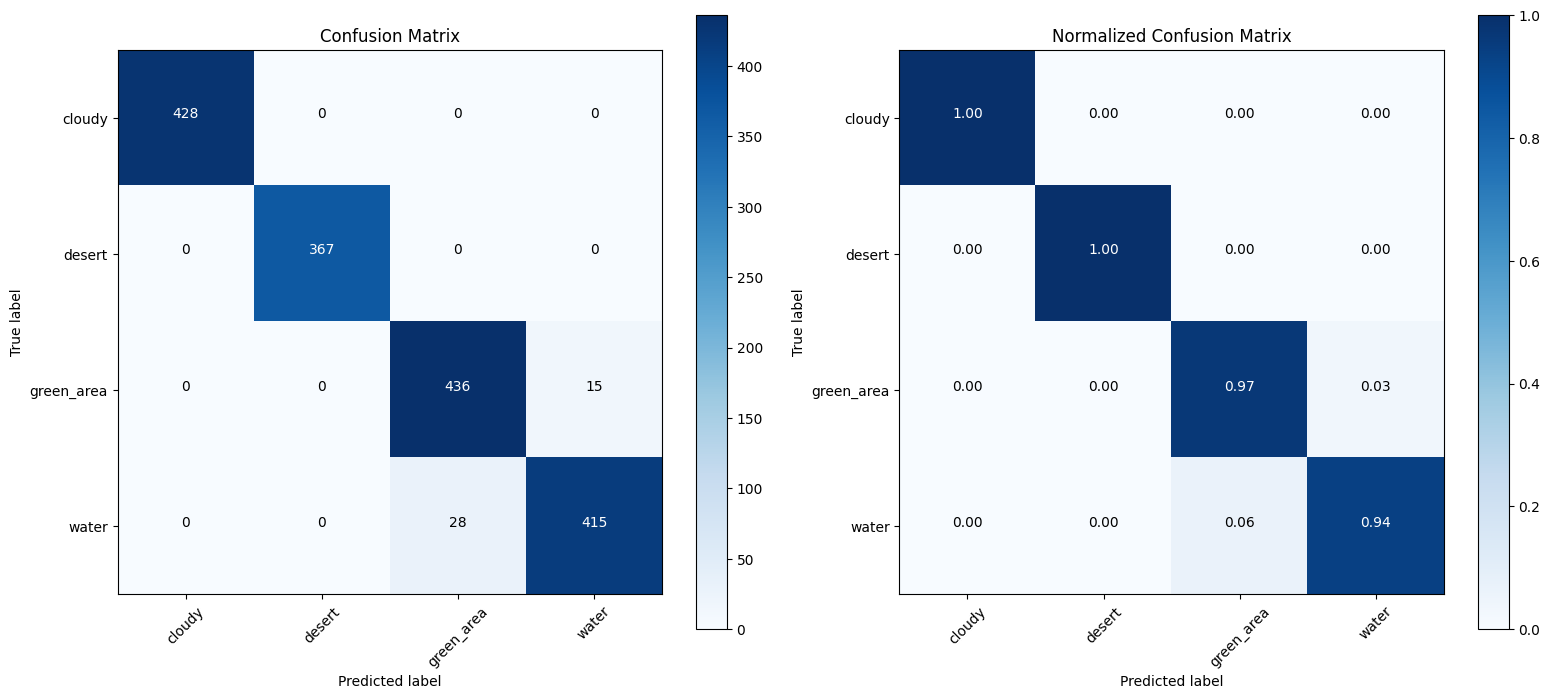

In [ ]:
plot_and_evaluate(model_alex, history_alex, test_X, test_y, class_names_list)

# MobileNet Model

This code uses MobileNet as a pretrained feature extractor by loading ImageNet weights and removing its original classification head. The MobileNet base is frozen to preserve the learned features, while a new classifier consisting of global average pooling and dense layers is added on top to adapt the model to the target number of classes using transfer learning.

In [ ]:
base_mobile = MobileNet(
    weights='imagenet',
    include_top=False,
    input_shape=(128,128,3)
)

base_mobile.trainable = False

model_mobile = Sequential([
    base_mobile,
    GlobalAveragePooling2D(),
    Dense(1024, activation='relu'),
    Dense(num_classes, activation='softmax')
])

17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
model_mobile.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [ ]:
model_mobile.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenet_1.00_128 (Functional) │ (None, 4, 4, 1024)     │     3,228,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1024)           │     1,049,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 4)              │         4,100 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,282,564 (16.34 MB)

 Trainable params: 1,053,700 (4.02 MB)

 Non-trainable params: 3,228,864 (12.32 MB)

In [ ]:
history_mobile = model_mobile.fit(train_X, train_y, epochs=200, validation_data=(test_X, test_y), callbacks=[early_stopping])

Epoch 1/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 55s 428ms/step - accuracy: 0.9295 - loss: 0.2189 - val_accuracy: 0.9870 - val_loss: 0.0438
Epoch 2/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 80s 412ms/step - accuracy: 0.9900 - loss: 0.0343 - val_accuracy: 0.9953 - val_loss: 0.0147
Epoch 3/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 83s 425ms/step - accuracy: 0.9940 - loss: 0.0172 - val_accuracy: 0.9941 - val_loss: 0.0214
Epoch 4/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 79s 404ms/step - accuracy: 0.9950 - loss: 0.0205 - val_accuracy: 0.9947 - val_loss: 0.0203
Epoch 5/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 89s 459ms/step - accuracy: 0.9970 - loss: 0.0087 - val_accuracy: 0.9953 - val_loss: 0.0117
Epoch 6/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 76s 409ms/step - accuracy: 0.9959 - loss: 0.0097 - val_accuracy: 0.9947 - val_loss: 0.0150
Epoch 7/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 109s 625ms/step - accuracy: 0.9984 - loss: 0.0057 - val_accuracy: 0.9964 - val_loss: 0.0137
Epoch 8/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 81s 613ms/step - accuracy: 0.9986 

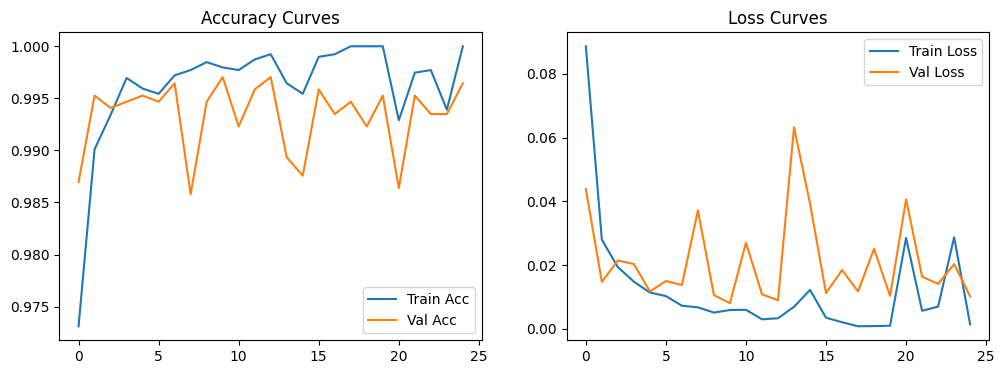

Training Accuracy: 100.00%
Test Accuracy: 99.70%

Classification Report:
               precision    recall  f1-score   support

      cloudy       1.00      1.00      1.00       428
      desert       1.00      1.00      1.00       367
  green_area       1.00      0.99      0.99       451
       water       0.99      1.00      0.99       443

    accuracy                           1.00      1689
   macro avg       1.00      1.00      1.00      1689
weighted avg       1.00      1.00      1.00      1689



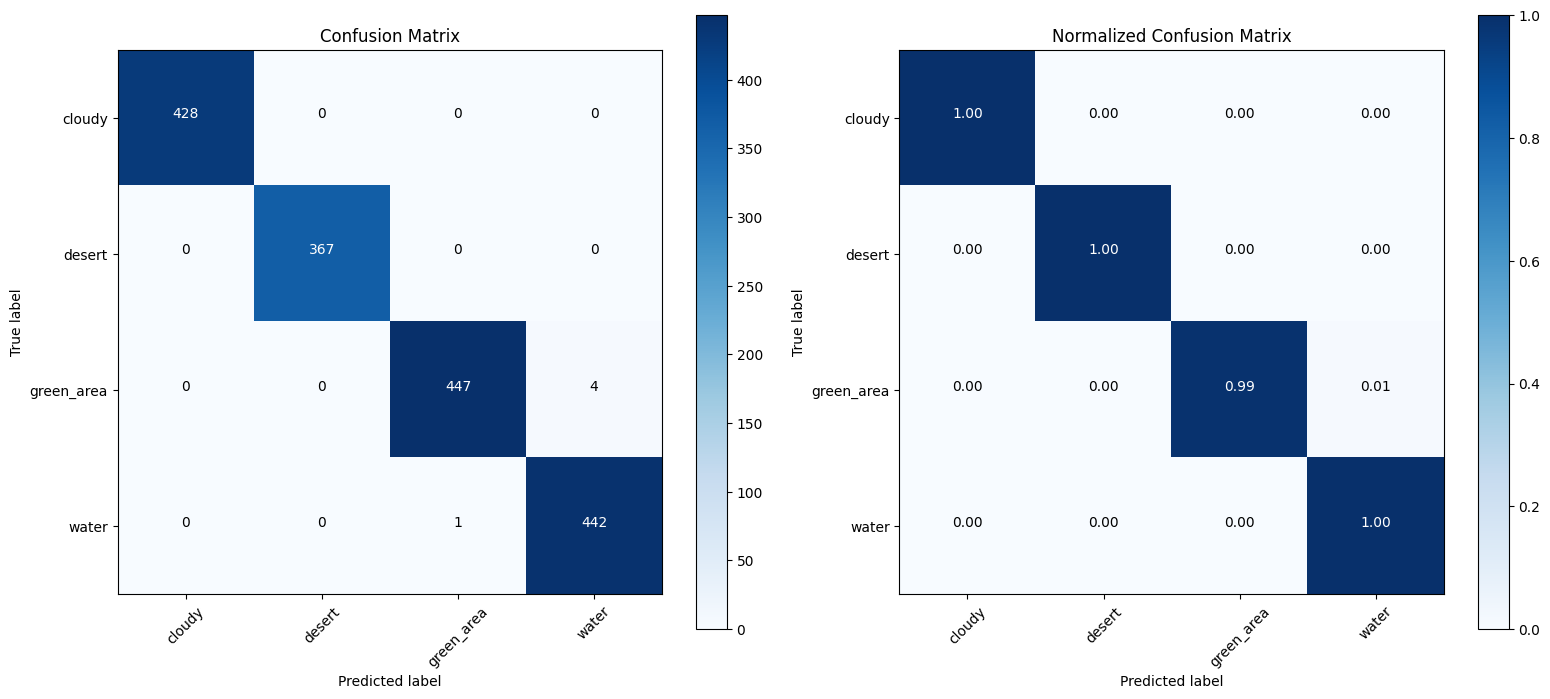

In [ ]:
plot_and_evaluate(model_mobile, history_mobile, test_X, test_y, class_names_list)

# ResNet50 Model

This code builds an improved image classification model using ResNet50 pretrained on ImageNet as a frozen feature extractor. The top classification layers are removed and replaced with global average pooling followed by dense layers, batch normalization, and dropout to improve learning stability and reduce overfitting. The final softmax layer outputs class probabilities, adapting the pretrained ResNet to the new classification task using transfer learning.

In [ ]:
def build_improved_resnet(input_shape, num_classes):
    base_resnet = ResNet50(weights='imagenet', include_top=False, input_shape=input_shape)
    base_resnet.trainable = False
    model = Sequential([
        base_resnet,
        GlobalAveragePooling2D(),
        Dense(512, activation='relu'),
        tf.keras.layers.BatchNormalization(),
        Dropout(0.4),
        Dense(256, activation='relu'),
        Dropout(0.3),
        Dense(num_classes, activation='softmax')
    ])
    return model
model_resnet = build_improved_resnet((128, 128, 3), num_classes)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
model_resnet.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [ ]:
model_resnet.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 4, 4, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,771,204 (94.49 MB)

 Trainable params: 1,182,468 (4.51 MB)

 Non-trainable params: 23,588,736 (89.98 MB)

In [ ]:
history_resnet = model_resnet.fit(train_X, train_y, epochs=200, validation_data=(test_X, test_y), callbacks=[early_stopping])

Epoch 1/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 206s 2s/step - accuracy: 0.8132 - loss: 0.5132 - val_accuracy: 0.2623 - val_loss: 7.8113
Epoch 2/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 195s 2s/step - accuracy: 0.9753 - loss: 0.0885 - val_accuracy: 0.2623 - val_loss: 10.6034
Epoch 3/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 216s 2s/step - accuracy: 0.9681 - loss: 0.0855 - val_accuracy: 0.2534 - val_loss: 17.6281
Epoch 4/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 217s 2s/step - accuracy: 0.9727 - loss: 0.0893 - val_accuracy: 0.3250 - val_loss: 12.2627
Epoch 5/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 216s 2s/step - accuracy: 0.9815 - loss: 0.0566 - val_accuracy: 0.2173 - val_loss: 17.5775
Epoch 6/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 219s 2s/step - accuracy: 0.9837 - loss: 0.0546 - val_accuracy: 0.2623 - val_loss: 58.0811
Epoch 7/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 222s 2s/step - accuracy: 0.9781 - loss: 0.0519 - val_accuracy: 0.5157 - val_loss: 27.9997
Epoch 8/200
124/124 ━━━━━━━━━━━━━━━━━━━━ 216s 2s/step - accuracy: 0.9791 - loss: 0.0

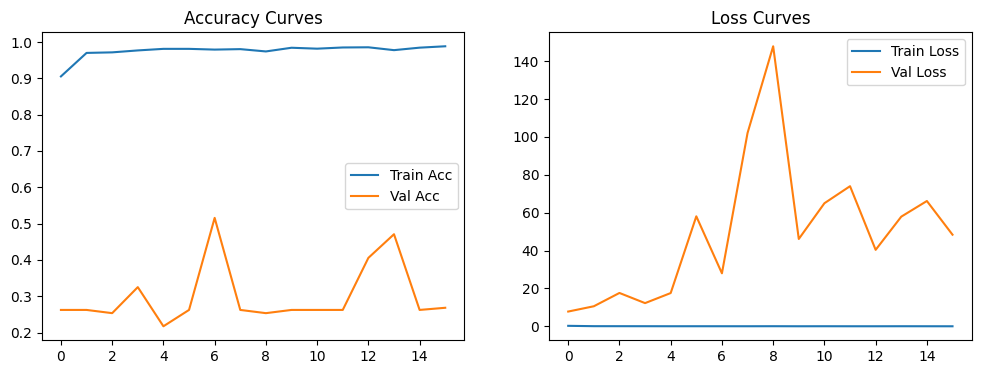

Training Accuracy: 98.81%
Test Accuracy: 26.23%

Classification Report:
               precision    recall  f1-score   support

      cloudy       0.00      0.00      0.00       428
      desert       0.00      0.00      0.00       367
  green_area       0.00      0.00      0.00       451
       water       0.26      1.00      0.42       443

    accuracy                           0.26      1689
   macro avg       0.07      0.25      0.10      1689
weighted avg       0.07      0.26      0.11      1689



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


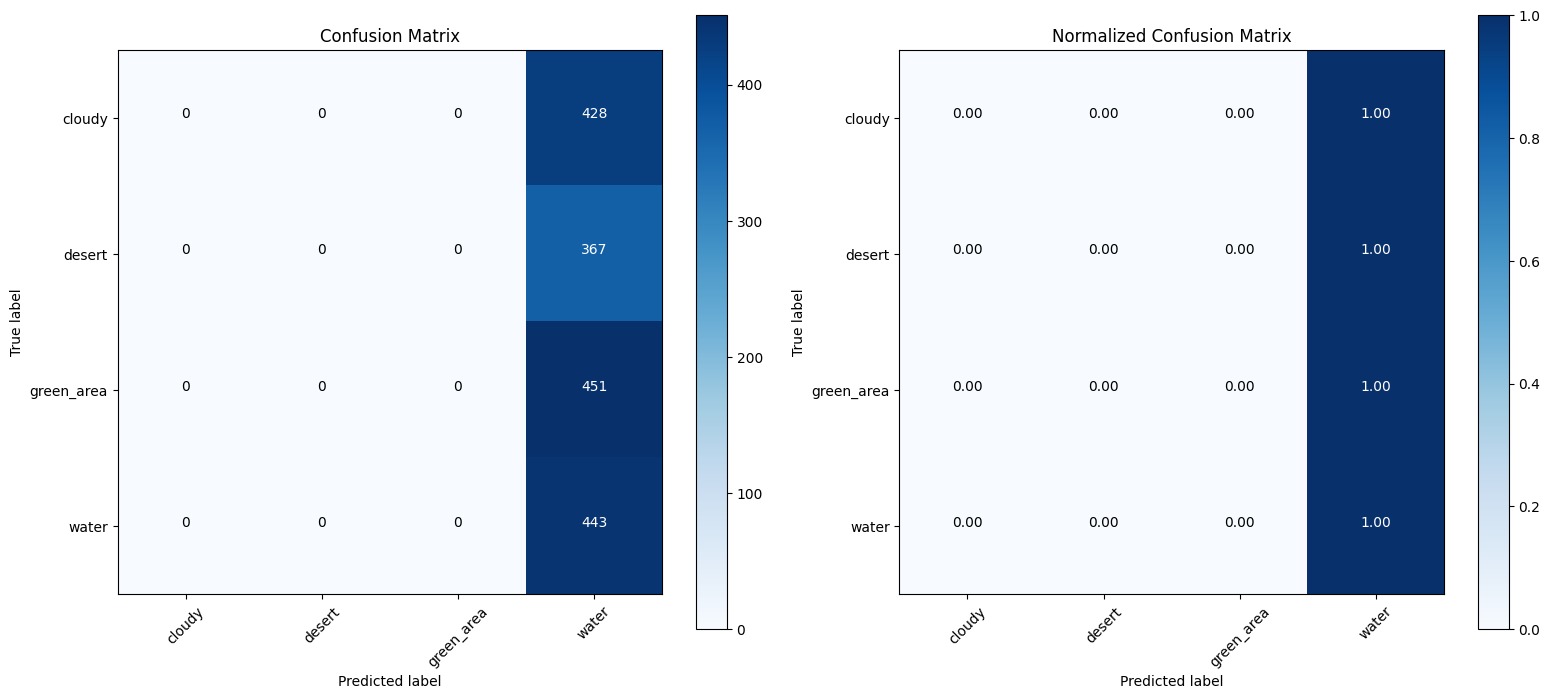

In [ ]:
plot_and_evaluate(model_resnet, history_resnet, test_X, test_y, class_names_list)

The table above summarizes the final training and validation accuracy and loss for each of the four models: Custom CNN, AlexNet, MobileNet, and ResNet50.

In [ ]:
results = {
    'Model': ['Custom CNN', 'AlexNet', 'MobileNet', 'ResNet50'],
    'Training Accuracy': [
        history_cnn.history['accuracy'][-1],
        history_alex.history['accuracy'][-1],
        history_mobile.history['accuracy'][-1],
        history_resnet.history['accuracy'][-1]
    ],
    'Validation Accuracy': [
        history_cnn.history['val_accuracy'][-1],
        history_alex.history['val_accuracy'][-1],
        history_mobile.history['val_accuracy'][-1],
        history_resnet.history['val_accuracy'][-1]
    ],
    'Training Loss': [
        history_cnn.history['loss'][-1],
        history_alex.history['loss'][-1],
        history_mobile.history['loss'][-1],
        history_resnet.history['loss'][-1]
    ],
    'Validation Loss': [
        history_cnn.history['val_loss'][-1],
        history_alex.history['val_loss'][-1],
        history_mobile.history['val_loss'][-1],
        history_resnet.history['val_loss'][-1]
    ]
}

results_df = pd.DataFrame(results)
results_df['Training Accuracy'] = results_df['Training Accuracy'].apply(lambda x: f'{x*100:.2f}%')
results_df['Validation Accuracy'] = results_df['Validation Accuracy'].apply(lambda x: f'{x*100:.2f}%')
results_df['Training Loss'] = results_df['Training Loss'].apply(lambda x: f'{x:.4f}')
results_df['Validation Loss'] = results_df['Validation Loss'].apply(lambda x: f'{x:.4f}')

display(results_df)

,Model,Training Accuracy,Validation Accuracy,Training Loss,Validation Loss
0,Custom CNN,95.64%,94.26%,0.1074,0.1388
1,AlexNet,96.32%,96.92%,0.0904,0.0827
2,MobileNet,100.00%,99.64%,0.0014,0.0102
3,ResNet50,98.81%,26.82%,0.0366,48.3811


# Get predictions from CNN and AlexNet and ResNet50

In [ ]:
pred_resnet = model_resnet.predict(test_X)
pred_mobile = model_mobile.predict(test_X)
pred_cnn    = model_cnn.predict(test_X)

53/53 ━━━━━━━━━━━━━━━━━━━━ 59s 1s/step
53/53 ━━━━━━━━━━━━━━━━━━━━ 13s 252ms/step
53/53 ━━━━━━━━━━━━━━━━━━━━ 11s 209ms/step


# Average the results to enhance performance
 This cancels out individual model errors

In [ ]:
combined_probs = (pred_resnet + pred_mobile + pred_cnn) / 3.0

# Final Class Selection

In [ ]:
final_ensemble_preds = np.argmax(combined_probs, axis=1)
y_true = np.argmax(test_y, axis=1)

# Final Performance Evaluation

In [ ]:
ensemble_accuracy = np.mean(final_ensemble_preds == y_true)
print(f"Triple Combined Architecture Accuracy: {ensemble_accuracy*100:.2f}%")

Triple Combined Architecture Accuracy: 98.40%


# Plot the Final Grid Matrix for the Combined Model

In [ ]:
print("Final Ensemble Classification Report:\n")
print(classification_report(y_true, final_ensemble_preds, target_names=class_names_list))

Final Ensemble Classification Report:

              precision    recall  f1-score   support

      cloudy       1.00      1.00      1.00       428
      desert       1.00      1.00      1.00       367
  green_area       1.00      0.94      0.97       451
       water       0.94      1.00      0.97       443

    accuracy                           0.98      1689
   macro avg       0.99      0.99      0.98      1689
weighted avg       0.98      0.98      0.98      1689



Use a green color map to distinguish the final combined result

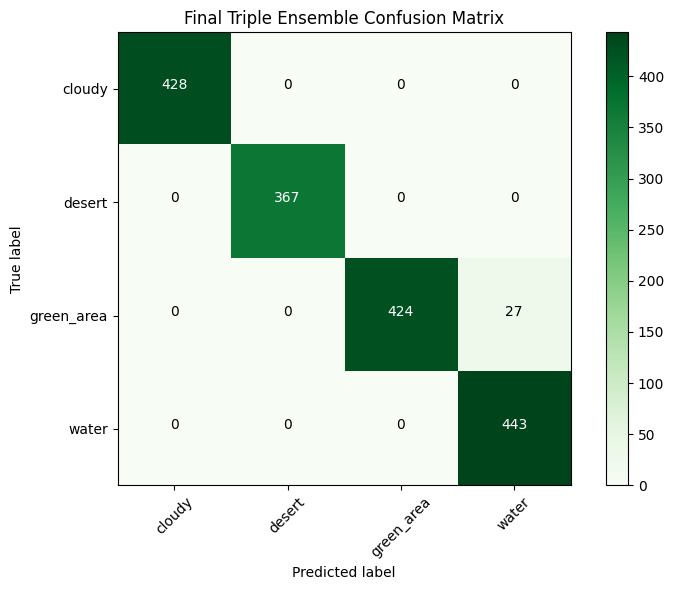

In [ ]:
cm = confusion_matrix(y_true, final_ensemble_preds)
plt.figure(figsize=(8, 6))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Greens)
plt.title('Final Triple Ensemble Confusion Matrix')
plt.colorbar()
tick_marks = np.arange(len(class_names_list))
plt.xticks(tick_marks, class_names_list, rotation=45)
plt.yticks(tick_marks, class_names_list)
fmt = 'd'
thresh = cm.max() / 2.
for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    plt.text(j, i, format(cm[i, j], fmt),
             horizontalalignment="center",
             color="white" if cm[i, j] > thresh else "black")

plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.tight_layout()
plt.show()